# LM10 Lab — Quadratic Forms and Covariance Matrices

Companion notebook to **From Calculus to Kelly, LM10**. It repairs the sector closes, rebuilds the module's exhibits and computational examples, solves the computational practice problems, and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 1 | The data: the repair of the sector closes, the U28 sample, $T$ and $A$ |
| 2 | Quadratic forms: the symmetric part and level curves (Example 1, Exhibit 2) |
| 3 | The sample covariance matrix three ways, $C$, Example 2, Example 3, the case (Exhibit 1, Exhibit 4) |
| 4 | Portfolio variance: `X @ w` against `w @ S @ w`, Example 4 and Exhibit 5, Example 5 |
| 5 | Tests of definiteness: minors, pivots, all principal minors, congruence (Example 6, Example 7, Exhibit 6) |
| 6 | Failures: rank against $T$ (Example 8, Exhibit 7), collinearity, missing values in software (Exhibit 11), pairwise deletion (Exhibit 8, Example 9, Exhibit 9) |
| 7 | Matrix calculus: gradients by finite differences, Example 10, the gradient and the level curves (Exhibit 10), convexity (10.10) |
| 8 | Practice problems 4, 5, 6, 9 and 11, and an extension exercise |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

`data/` then holds `sectors_close_raw.csv` (the daily closes FinMind's `TaiwanStockPrice` serves for TAIEX and the 30 TWSE sector indices, one column each, empty where a series has no close), `sectors_close_repairs.csv` (every close that the book repairs, with its 13:30:00 value from `TaiwanStockEvery5SecondsIndex`), and the closes and cash dividends of 0050, 00631L and 00679B. The notebook reads nothing outside `data/`.

**Conventions (as in the module).** U28 is the 28 leaf sector indices among the 30 TWSE sector indices that FinMind serves daily (all except the aggregates Electronic and ChemicalBiotechnologyMedicalCare); S3 is Semiconductor, FinancialInsurance and Food, and S5 adds Plastics and ShippingTransportation. Daily simple price returns between consecutive TAIEX-calendar dates, closes from 2008-12-01 to 2026-10-08; moments with divisor $T$; $A=T/\text{years}$ with years = calendar days / 365.25. Weights are rebalanced daily.

In [1]:
from pathlib import Path
from datetime import date
from fractions import Fraction
from itertools import combinations, permutations
import math
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

DATA = Path("data")
FIRST, LAST = "2008-12-01", "2026-10-08"
AGGREGATES = ["Electronic", "ChemicalBiotechnologyMedicalCare"]
S3 = ["Semiconductor", "FinancialInsurance", "Food"]
S5 = S3 + ["Plastics", "ShippingTransportation"]
ETFS = ["0050", "00631L", "00679B"]
np.set_printoptions(precision=6, suppress=True, linewidth=110)
pl.Config.set_tbl_rows(40)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def cov0(x):
    # sample covariance matrix, divisor T, columns = variables: (10.2)
    xc = x - x.mean(axis=0)
    return xc.T @ xc / x.shape[0]

def pivots(M):
    # pivots of Gaussian elimination without row exchanges; stops at the first that is not positive
    M = np.array(M, dtype=float)
    out = []
    for k in range(len(M)):
        out.append(M[k, k])
        if M[k, k] <= 0:
            break
        M[k + 1:] -= np.outer(M[k + 1:, k] / M[k, k], M[k])
    return np.array(out)

## Part 1 — The data: repair, sample, $T$ and $A$

FinMind's daily sector series copies some closes from other dates or from another series (`data/README.md` in the repository). The book replaces each of those closes with the official 13:30:00 value from `TaiwanStockEvery5SecondsIndex`. `sectors_close_repairs.csv` lists all 561 of them; its `close_1330` column is empty when that file was not downloaded, because the dataset needs a paid FinMind plan.

**Rule.** Replace every listed close by its 13:30:00 value; when the value is missing, drop the close. Returns stay between consecutive TAIEX-calendar dates, so a dropped close removes the returns into and out of its date.

In [2]:
raw = pl.read_csv(DATA / "sectors_close_raw.csv", infer_schema_length=None)
rep = pl.read_csv(DATA / "sectors_close_repairs.csv", infer_schema_length=None,
                  schema_overrides={"close_1330": pl.Float64})
ids = [c for c in raw.columns if c not in ("date", "TAIEX")]
U28 = [c for c in ids if c not in AGGREGATES]
assert len(ids) == 30 and len(U28) == 28
closes = raw.with_columns([pl.col(c).cast(pl.Float64) for c in raw.columns if c != "date"])
for sid in sorted(set(rep["id"].to_list())):
    r = rep.filter(pl.col("id") == pl.lit(sid)).select(
        "date", pl.col("close_1330").alias("_new"), pl.lit(True).alias("_listed"))
    closes = (closes.join(r, on="date", how="left")
              .with_columns(pl.when(pl.col("_listed")).then(pl.col("_new")).otherwise(pl.col(sid)).alias(sid))
              .drop("_new", "_listed"))
closes = closes.sort("date")                     # never rely on row order after a join
n_listed = rep.height
n_replaced = rep.filter(pl.col("close_1330").is_not_null()).height
in_smp = rep.filter(pl.col("id").is_in(U28) & pl.col("date").is_between(pl.lit(FIRST), pl.lit(LAST)))
print("Rule: replace each listed close by its 13:30:00 value; drop it when the value is missing.")
print(f"listed closes {n_listed}: replaced {n_replaced}, dropped {n_listed - n_replaced}")
print(f"listed closes in this module's sample (U28, {FIRST} .. {LAST}): {in_smp.height} on {in_smp['date'].n_unique()} dates")
FULL = n_replaced == n_listed

Rule: replace each listed close by its 13:30:00 value; drop it when the value is missing.
listed closes 561: replaced 561, dropped 0
listed closes in this module's sample (U28, 2008-12-01 .. 2026-10-08): 524 on 38 dates


In [3]:
smp = closes.filter(pl.col("date").is_between(pl.lit(FIRST), pl.lit(LAST))).sort("date")
ret = (smp.select("date", *[(pl.col(c) / pl.col(c).shift(1) - 1).alias(c) for c in ["TAIEX", *U28]])
          .slice(1).drop_nulls(subset=U28))
X = ret.select(U28).to_numpy()
taiex = ret["TAIEX"].to_numpy()
dates = ret["date"].to_list()
T = X.shape[0]
years = (date.fromisoformat(smp["date"][-1]) - date.fromisoformat(smp["date"][0])).days / 365.25
A = T / years
print(f"U28 sample: T = {T} returns, {dates[0]} .. {dates[-1]}; years = {years:.8f}; A = {A:.4f}")
print(f"A = {T} x 365.25 / {round(years * 365.25)} = {A:.2f}")
if FULL:
    assert T == 4382 and dates[0] == "2008-12-02"
else:
    print(f"free plan: {4382 - T} of the module's 4,382 returns are missing (see the note below)")

U28 sample: T = 4382 returns, 2008-12-02 .. 2026-10-08; years = 17.85078713; A = 245.4794
A = 4382 x 365.25 / 6520 = 245.48


**On FinMind's free plan** `close_1330` is empty, the cell above drops the 561 listed closes, and U28's sample keeps $T=4{,}307$ of the 4,382 returns ($A=241.28$). Numbers computed inside a window without a listed close, or from printed inputs, keep the module's values: Example 2 (7–9 April 2025), Example 6 and Example 7 (printed matrices), Example 8 and Exhibit 7 (the latest 35 returns), Example 9 and Exhibit 9 (ETF returns only), Problem 4 (printed inputs) and the extension's years 2014, 2023, 2024 and 2026. Every other number uses the full sample, or $A$, and changes: the case and Exhibit 1, $\hat\Sigma$ and $C$, Example 3, Example 4, Example 5, Example 10, Exhibit 8 and Problems 5, 6, 9 and 11 (Getting Started, "Fetch the data").

## Part 2 — Quadratic forms (Example 1, Exhibit 2)

A quadratic form $\mathbf x^{\top}M\mathbf x$ meets $m_{ij}$ and $m_{ji}$ with the same product $x_ix_j$, so it equals $\mathbf x^{\top}M_{\text{sym}}\mathbf x$ (10.1).

x = [ 1. -1.]: x'Mx = -2.00, x'M_sym x = -2.00
x = [2. 1.]: x'Mx = +13.00, x'M_sym x = +13.00
x = [-3.   0.5]: x'Mx = +3.25, x'M_sym x = +3.25
det M = 1 (says nothing about the form); det M_sym = -3 (indefinite)


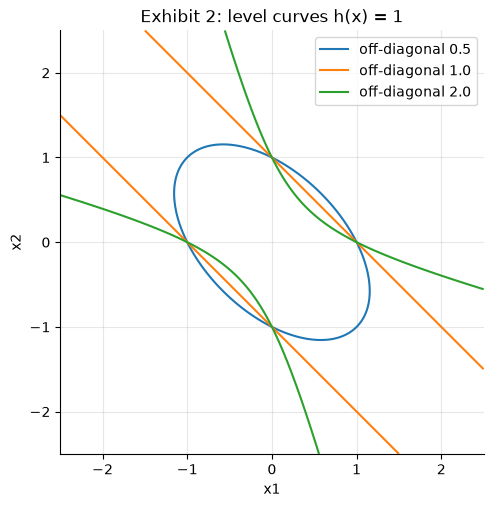

In [4]:
M = np.array([[1.0, 4.0], [0.0, 1.0]])
Msym = (M + M.T) / 2
for v in (np.array([1.0, -1.0]), np.array([2.0, 1.0]), np.array([-3.0, 0.5])):
    print(f"x = {v}: x'Mx = {v @ M @ v:+.2f}, x'M_sym x = {v @ Msym @ v:+.2f}")
print(f"det M = {np.linalg.det(M):.0f} (says nothing about the form); det M_sym = {np.linalg.det(Msym):.0f} (indefinite)")

g = np.linspace(-2.5, 2.5, 501)
x1, x2 = np.meshgrid(g, g)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for off, col in ((0.5, "tab:blue"), (1.0, "tab:orange"), (2.0, "tab:green")):
    ax.contour(x1, x2, x1**2 + 2 * off * x1 * x2 + x2**2, levels=[1.0], colors=[col])
    ax.plot([], [], color=col, label=f"off-diagonal {off}")
ax.set_aspect("equal"); ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(loc="upper right")
ax.set_title("Exhibit 2: level curves h(x) = 1"); plt.show()

## Part 3 — The sample covariance matrix (Example 2, Example 3, Exhibit 1, Exhibit 4)

Three ways to build $\hat\Sigma$ from (10.2): the matrix product of the centred returns, `np.cov` with the right options, and the sum of $T$ outer products.

In [5]:
Xc = X - X.mean(axis=0)
S = Xc.T @ Xc / T
S_np = np.cov(X, rowvar=False, ddof=0)
S_outer = sum(np.outer(row, row) for row in Xc) / T
print("shapes:", X.shape, Xc.shape, S.shape)
print("the three agree within 1e-15:", max(np.abs(S - S_np).max(), np.abs(S - S_outer).max()) < 1e-15)
assert max(np.abs(S - S_np).max(), np.abs(S - S_outer).max()) < 1e-15
print("every column of the centred matrix sums to zero:", np.abs(Xc.sum(axis=0)).max() < 1e-12)
s = np.sqrt(np.diag(S))
C = S / np.outer(s, s)
vol = s * math.sqrt(A)
print(f"distinct entries: {28 * 29 // 2} = 28 variances + {28 * 27 // 2} covariances")

shapes: (4382, 28) (4382, 28) (28, 28)
the three agree within 1e-15: True
every column of the centred matrix sums to zero: True
distinct entries: 406 = 28 variances + 378 covariances


In [6]:
# Example 2: Semiconductor and FinancialInsurance on 7, 8 and 9 April 2025 (7 April runs from 2 April)
w4 = closes.filter(pl.col("date").is_in(["2025-04-02", "2025-04-07", "2025-04-08", "2025-04-09"])).sort("date")
print(w4.select("date", "Semiconductor", "FinancialInsurance"))
Rs = [round(100 * (b / a - 1), 2) for a, b in zip(w4["Semiconductor"][:-1], w4["Semiconductor"][1:])]
Rf = [round(100 * (b / a - 1), 2) for a, b in zip(w4["FinancialInsurance"][:-1], w4["FinancialInsurance"][1:])]
print("returns (%):", Rs, Rf)
# hand arithmetic in exact decimals, from the rounded returns, as the example does
F = lambda x: Fraction(str(x))
ms, mf = sum(map(F, Rs)) / 3, sum(map(F, Rf)) / 3
ds = [round(float(F(r) - ms), 4) for r in Rs]
df_ = [round(float(F(r) - mf), 2) for r in Rf]
print(f"means {float(ms):.4f} {float(mf):.2f}; deviations {ds} {df_}")
prod = [(round(a * a, 4), round(a * b, 4), round(b * b, 4)) for a, b in zip(ds, df_)]
for row in prod:
    print("products", row)
sig = [sum(F(p[k]) for p in prod) / 3 for k in range(3)]
print("sigma_11, sigma_12, sigma_22 (%^2):", [f"{float(v):.4f}" for v in sig])
print(f"rho = {9.8339 / math.sqrt(7.3092 * 18.2883):.3f}")

shape: (4, 3)
┌────────────┬───────────────┬────────────────────┐
│ date       ┆ Semiconductor ┆ FinancialInsurance │
│ ---        ┆ ---           ┆ ---                │
│ str        ┆ f64           ┆ f64                │
╞════════════╪═══════════════╪════════════════════╡
│ 2025-04-02 ┆ 586.06        ┆ 2109.23            │
│ 2025-04-07 ┆ 527.73        ┆ 1900.64            │
│ 2025-04-08 ┆ 506.65        ┆ 1910.69            │
│ 2025-04-09 ┆ 484.0         ┆ 1803.56            │
└────────────┴───────────────┴────────────────────┘
returns (%): [-9.95, -3.99, -4.47] [-9.89, 0.53, -5.61]
means -6.1367 -4.99; deviations [-3.8133, 2.1467, 1.6667] [-4.9, 5.52, -0.62]
products (14.5413, 18.6852, 24.01)
products (4.6083, 11.8498, 30.4704)
products (2.7779, -1.0334, 0.3844)
sigma_11, sigma_12, sigma_22 (%^2): ['7.3092', '9.8339', '18.2883']
rho = 0.851


In [7]:
# Example 3: the S3 block, annualized, in %^2, printed to two decimals
i3 = [U28.index(n) for n in S3]
AS3 = np.round(1e4 * A * S[np.ix_(i3, i3)], 2)
print("A Sigma_3 (%^2):\n", AS3)
v3 = np.sqrt(np.diag(AS3))
print("volatilities (%):", v3.round(2))
C3 = AS3 / np.outer(v3, v3)
print("C_3 from the printed matrix:\n", C3.round(3))
print("C_3 from the data:\n", C[np.ix_(i3, i3)].round(3))
print(f"way back: 23.88 x 19.07 x 0.575 = {23.88 * 19.07 * 0.575:.2f}")

A Sigma_3 (%^2):
 [[570.34 261.83 162.26]
 [261.83 363.73 191.35]
 [162.26 191.35 283.54]]
volatilities (%): [23.88 19.07 16.84]
C_3 from the printed matrix:
 [[1.    0.575 0.403]
 [0.575 1.    0.596]
 [0.403 0.596 1.   ]]
C_3 from the data:
 [[1.    0.575 0.403]
 [0.575 1.    0.596]
 [0.403 0.596 1.   ]]
way back: 23.88 x 19.07 x 0.575 = 261.85


least volatile CommunicationsInternet 13.67%, most GlassCeramic 35.31%, mean 21.94%
equal-weight book 15.75%; sectors below it: ['CommunicationsInternet']
TAIEX on the same dates 17.82%; variance terms alone 4.22%


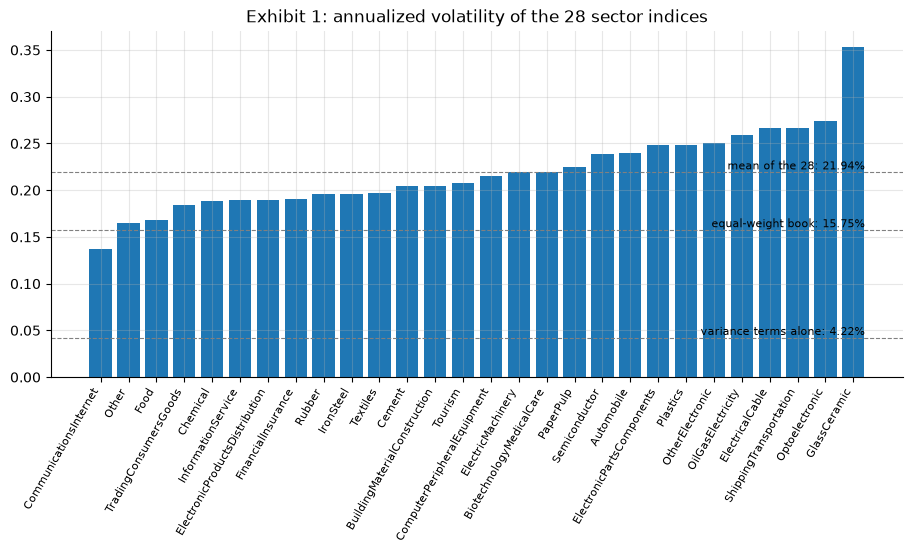

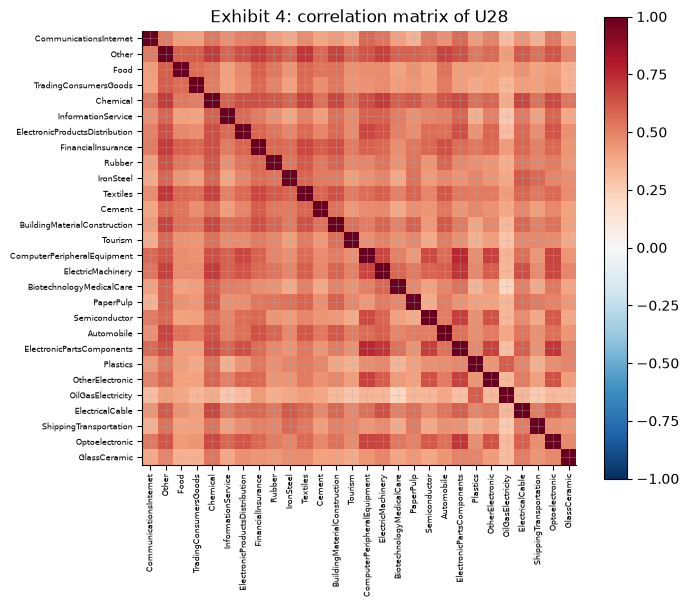

correlations from 0.217 to 0.755, mean 0.502
divisor T-1 multiplies a volatility by sqrt(T/(T-1)) = 1.000114


In [8]:
# the case and Exhibit 1
w = np.full(28, 1 / 28)
book = math.sqrt(A * w @ S @ w)
order = np.argsort(vol)
print(f"least volatile {U28[order[0]]} {vol[order[0]]:.2%}, most {U28[order[-1]]} {vol[order[-1]]:.2%}, mean {vol.mean():.2%}")
print(f"equal-weight book {book:.2%}; sectors below it: {[U28[k] for k in range(28) if vol[k] < book]}")
print(f"TAIEX on the same dates {math.sqrt(A) * taiex.std():.2%}; variance terms alone {math.sqrt(A * np.sum(w**2 * s**2)):.2%}")
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(range(28), vol[order], color="tab:blue")
ax.set_xticks(range(28)); ax.set_xticklabels([U28[k] for k in order], rotation=60, ha="right", fontsize=8)
for y, lab in ((vol.mean(), "mean of the 28"), (book, "equal-weight book"), (math.sqrt(A * np.sum(w**2 * s**2)), "variance terms alone")):
    ax.axhline(y, ls="--", color="grey", lw=0.8); ax.text(27.4, y, f"{lab}: {y:.2%}", ha="right", va="bottom", fontsize=8)
ax.set_title("Exhibit 1: annualized volatility of the 28 sector indices"); plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(C[np.ix_(order, order)], vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(28)); ax.set_yticks(range(28))
ax.set_xticklabels([U28[k] for k in order], rotation=90, fontsize=6); ax.set_yticklabels([U28[k] for k in order], fontsize=6)
fig.colorbar(im); ax.set_title("Exhibit 4: correlation matrix of U28"); plt.show()
off = ~np.eye(28, dtype=bool)
print(f"correlations from {C[off].min():.3f} to {C[off].max():.3f}, mean {C[off].mean():.3f}")
print(f"divisor T-1 multiplies a volatility by sqrt(T/(T-1)) = {math.sqrt(T / (T - 1)):.6f}")

## Part 4 — Portfolio variance (Example 4, Exhibit 5, Example 5)

For constant weights the book's daily returns are `X @ w`, and their divisor-$T$ variance is exactly `w @ S @ w` (10.4).

In [9]:
print(f"np.var(X @ w) = {np.var(X @ w):.12e}; w @ S @ w = {w @ S @ w:.12e}; gap below 1e-15: {abs(np.var(X @ w) - w @ S @ w) < 1e-15}")
wm = np.array([0.5, 0.3, 0.2])
cells = 1e4 * A * np.outer(wm, wm) * S[np.ix_(i3, i3)]
print("Exhibit 5 (%^2):\n", cells.round(2), "\ntotal", f"{cells.sum():.2f}", "; volatility", f"{math.sqrt(cells.sum()):.2f}%")
print(f"from the printed matrix: {wm @ AS3 @ wm:.2f} (%^2)")
print(f"weighted average of the volatilities: {wm @ np.sqrt(A * np.diag(S[np.ix_(i3, i3)])):.2%}")

np.var(X @ w) = 1.010406607793e-04; w @ S @ w = 1.010406607793e-04; gap below 1e-15: True
Exhibit 5 (%^2):
 [[142.58  39.27  16.23]
 [ 39.27  32.74  11.48]
 [ 16.23  11.48  11.34]] 
total 320.62 ; volatility 17.91%
from the printed matrix: 320.63 (%^2)
weighted average of the volatilities: 21.03%


In [10]:
vbar, cbar = np.mean(np.diag(S)), S[off].mean()
print(f"Example 5: vbar = {vbar:.4e}, cbar = {cbar:.4e} (daily)")
sp2 = vbar / 28 + (1 - 1 / 28) * cbar
print(f"(10.6): {vbar / 28:.4e} + {(1 - 1 / 28) * cbar:.4e} = {sp2:.4e}; w'Sw = {w @ S @ w:.4e}")
print(f"annualized {A * sp2:.6f}, volatility {math.sqrt(A * sp2):.2%}; covariance share {(1 - 1 / 28) * cbar / sp2:.1%}")
print(f"variance terms alone {math.sqrt(A * vbar / 28):.2%}; limit sqrt(A cbar) = {math.sqrt(A * cbar):.2%}")

Example 5: vbar = 2.0328e-04, cbar = 9.7254e-05 (daily)
(10.6): 7.2600e-06 + 9.3781e-05 = 1.0104e-04; w'Sw = 1.0104e-04
annualized 0.024803, volatility 15.75%; covariance share 92.8%
variance terms alone 4.22%; limit sqrt(A cbar) = 15.45%


## Part 5 — Tests of definiteness (Example 6, Example 7, Exhibit 6)

Leading principal minors and pivots decide positive definiteness (tests 2 and 3); positive semidefiniteness needs every principal minor (test 4). Exact fractions avoid floating-point residues.

In [11]:
def principal_minors(M):
    n = len(M)
    out = {}
    for k in range(1, n + 1):
        for idx in combinations(range(n), k):
            out[idx] = np.linalg.det(np.asarray(M, dtype=float)[np.ix_(idx, idx)]) if k > 1 else float(M[idx[0]][idx[0]])
    return out

C3p = np.array([[1, 0.575, 0.403], [0.575, 1, 0.596], [0.403, 0.596, 1]])
lead = [np.linalg.det(C3p[:k, :k]) for k in (1, 2, 3)]
print("Example 6 leading minors:", [f"{v:.6f}" for v in lead], " pivots:", pivots(C3p).round(4))
print("all seven principal minors positive:", all(v > 0 for v in principal_minors(C3p).values()))

D2 = np.diag([0.0, -1.0])
print("diag(0,-1): leading minors", [float(D2[0, 0]), float(np.linalg.det(D2))],
      "; principal minors", {k: float(v) for k, v in principal_minors(D2).items()})

Fr = Fraction
M7 = [[Fr(570), Fr(262), Fr(416)], [Fr(262), Fr(364), Fr(313)], [Fr(416), Fr(313), Fr(729, 2)]]
det3 = lambda m: (m[0][0] * (m[1][1] * m[2][2] - m[1][2] * m[2][1]) - m[0][1] * (m[1][0] * m[2][2] - m[1][2] * m[2][0])
                  + m[0][2] * (m[1][0] * m[2][1] - m[1][1] * m[2][0]))
minors2 = [M7[0][0] * M7[1][1] - M7[0][1] ** 2, M7[0][0] * M7[2][2] - M7[0][2] ** 2, M7[1][1] * M7[2][2] - M7[1][2] ** 2]
print("Example 7 (b): 2x2 minors", [str(v) for v in minors2], "; det", det3(M7))
xz = [Fr(1, 2), Fr(1, 2), Fr(-1)]
print("x'Mx at (0.5, 0.5, -1):", sum(xz[i] * M7[i][j] * xz[j] for i in range(3) for j in range(3)))

Example 6 leading minors: ['1.000000', '0.669375', '0.427966']  pivots: [1.     0.6694 0.6394]
all seven principal minors positive: True
diag(0,-1): leading minors [0.0, 0.0] ; principal minors {(0,): 0.0, (1,): -1.0, (0, 1): 0.0}
Example 7 (b): 2x2 minors ['138836', '34709', '34709'] ; det 0
x'Mx at (0.5, 0.5, -1): 0


In [12]:
# test 5 (congruence): C = K' S K with K = diag(1/s) is PSD exactly when S is; pivots of both, U28
K = np.diag(1 / s)
print("C equals K'SK:", np.allclose(K.T @ S @ K, C))
print("smallest pivot of S:", f"{pivots(S).min():.3e}", "; of C:", f"{pivots(C).min():.4f}", "(both positive: PD)")

C equals K'SK: True
smallest pivot of S: 3.182e-05 ; of C: 0.2888 (both positive: PD)


## Part 6 — When $\hat\Sigma$ fails (Example 8, Exhibit 7, Exhibit 11, Exhibit 8, Example 9, Exhibit 9)

rank of S on the latest T returns: {20: 19, 21: 20, 22: 21, 23: 22, 24: 23, 25: 24, 26: 25, 27: 26, 28: 27, 29: 28, 30: 28, 31: 28, 32: 28, 33: 28, 34: 28, 35: 28}
all equal min(T-1, 28): True ; T = 28 starts 2026-08-28 , T = 29 starts 2026-08-27


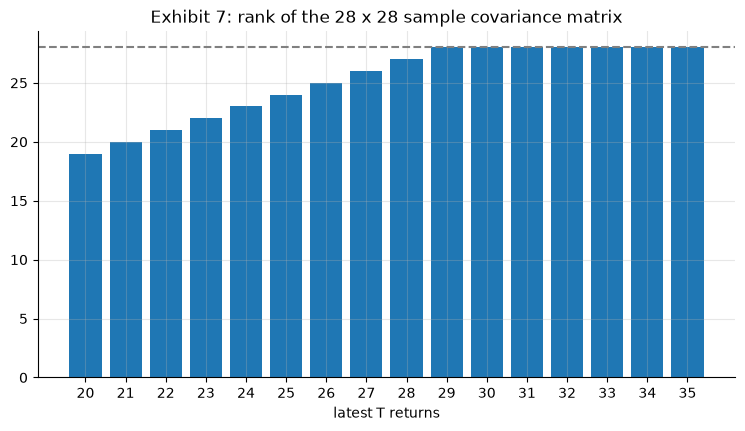

S5 plus its equal-weight book: rank 5 ; x'Sx below 1e-15: True


In [13]:
ranks = {t: int(np.linalg.matrix_rank(cov0(X[-t:]))) for t in range(20, 36)}
print("rank of S on the latest T returns:", ranks)
print("all equal min(T-1, 28):", all(r == min(t - 1, 28) for t, r in ranks.items()), "; T = 28 starts", dates[-28], ", T = 29 starts", dates[-29])
fig, ax = plt.subplots()
ax.bar([str(t) for t in ranks], list(ranks.values())); ax.axhline(28, ls="--", color="grey")
ax.set_xlabel("latest T returns"); ax.set_title("Exhibit 7: rank of the 28 x 28 sample covariance matrix"); plt.show()

i5 = [U28.index(n) for n in S5]
X6 = np.column_stack([X[:, i5], X[:, i5].mean(axis=1)])
S6 = cov0(X6)
x6 = np.array([0.2] * 5 + [-1.0])
print("S5 plus its equal-weight book: rank", np.linalg.matrix_rank(S6),
      "; x'Sx below 1e-15:", abs(x6 @ S6 @ x6) < 1e-15)

In [14]:
# Exhibit 11: what NumPy and Polars do with missing values (Polars documents no rule; observed here)
demo = pl.DataFrame({"a": [1.0, 2.0, None, 4.0, 5.0], "b": [2.0, 1.0, 3.0, None, 7.0]})
both = demo.drop_nulls()
print("Polars", pl.__version__)
print("pl.cov(a, b)            :", demo.select(pl.cov("a", "b")).item(), "| np.cov on the rows where both exist:", np.cov(both["a"], both["b"])[0, 1])
print("pl.cov(a, b, ddof=0)    :", demo.select(pl.cov("a", "b", ddof=0)).item())
print("pl.corr(a, b)           :", demo.select(pl.corr("a", "b")).item(), "| np.corrcoef on the same rows:", np.corrcoef(both["a"], both["b"])[0, 1])
print("DataFrame.corr():"); print(demo.corr())
xn = np.array([[1.0, 2.0, 0.5], [2.0, 1.0, 1.5], [np.nan, 3.0, 2.0], [4.0, 5.0, 1.0]])
print("np.cov with a NaN in column 0:\n", np.cov(xn, rowvar=False, ddof=0))

Polars 2.0.0
pl.cov(a, b)            : 6.166666666666666 | np.cov on the rows where both exist: 6.166666666666667
pl.cov(a, b, ddof=0)    : 4.111111111111111
pl.corr(a, b)           : 0.921550640565428 | np.corrcoef on the same rows: 0.9215506405654282
DataFrame.corr():
shape: (2, 2)
┌─────┬─────┐
│ a   ┆ b   │
│ --- ┆ --- │
│ f64 ┆ f64 │
╞═════╪═════╡
│ NaN ┆ NaN │
│ NaN ┆ NaN │
└─────┴─────┘
np.cov with a NaN in column 0:
 [[    nan     nan     nan]
 [    nan  2.1875 -0.0625]
 [    nan -0.0625  0.3125]]


**One-session total returns** of the three ETFs: $R_t=(P_t+D_t)/P_{t-1}-1$ between consecutive TAIEX-calendar dates on which the fund has both closes, with the cash dividend of every row of its dividends file. A return that spans a trading halt drops out, so the two split days (0050 on 2025-06-18, 00631L on 2026-03-31, both after a halt) need no split factor here; the cell checks that.

In [15]:
cal = closes["date"].to_list()

def one_session(sym):
    px = pl.read_csv(DATA / f"{sym}_daily_raw.csv").select("date", pl.col("close").cast(pl.Float64)).unique(subset="date").sort("date")
    f = DATA / f"{sym}_dividends.csv"
    div = (pl.read_csv(f).select("date", pl.col("cash_dividend").cast(pl.Float64).alias("D")) if f.exists()
           else pl.DataFrame(schema={"date": pl.String, "D": pl.Float64}))
    g = (pl.DataFrame({"date": cal}).join(px, on="date", how="left").sort("date")
         .join(div, on="date", how="left").sort("date")
         .with_columns(pl.col("D").fill_null(0.0), pl.col("close").shift(1).alias("prev")))
    out = g.with_columns(((pl.col("close") + pl.col("D")) / pl.col("prev") - 1).alias(sym)).select("date", sym).drop_nulls(sym)
    return dict(zip(out["date"].to_list(), out[sym].to_list()))

etf = {e: one_session(e) for e in ETFS}
print({e: len(v) for e, v in etf.items()}, "| split days present:", "2025-06-18" in etf["0050"], "2026-03-31" in etf["00631L"])
assert [len(etf[e]) for e in ETFS] == [2905, 2906, 2368]

{'0050': 2905, '00631L': 2906, '00679B': 2368} | split days present: False False


In [16]:
# Exhibit 8: U28 plus the three ETFs on U28's dates, common sample against pairwise deletion
cols = U28 + ETFS
Z = np.full((T, 31), np.nan)
Z[:, :28] = X
for j, e in enumerate(ETFS):
    Z[:, 28 + j] = [etf[e].get(d, np.nan) for d in dates]
ok = ~np.isnan(Z)
n = 31
Cp, Sp, cnt = np.eye(n), np.zeros((n, n)), np.zeros((n, n), dtype=int)
for i in range(n):
    Sp[i, i] = Z[ok[:, i], i].var()
    for j in range(i + 1, n):
        m = ok[:, i] & ok[:, j]
        cnt[i, j] = cnt[j, i] = m.sum()
        u, v = Z[m, i], Z[m, j]
        Cp[i, j] = Cp[j, i] = np.corrcoef(u, v)[0, 1]
        Sp[i, j] = Sp[j, i] = np.mean((u - u.mean()) * (v - v.mean()))
allm = ok.all(axis=1)
Sc, Cc = cov0(Z[allm]), np.corrcoef(Z[allm].T)
offc = cnt[np.triu_indices(n, 1)]
print(f"common sample: T = {allm.sum()} from {dates[int(np.argmax(allm))]}; pairwise counts {offc.min()} .. {offc.max()}")
first_common = dates[int(np.argmax(allm))]
halt = [d for d, a in zip(dates, allm) if d >= first_common and not a]
print(f"it drops {sum(d < first_common for d in dates)} returns before {first_common} and {len(halt)} dates after it: {halt}")
for name, Mx in (("C_pw", Cp), ("S_pw", Sp), ("common C", Cc), ("common S", Sc)):
    p = pivots(Mx)
    print(f"{name:10s}: {len(p)} pivots computed, last {p[-1]:.3e}", "-> not PSD" if p[-1] <= 0 else "-> PD")
iS = U28.index("Semiconductor"); i631 = 28 + ETFS.index("00631L")
print(f"Semiconductor's variance: all returns {Sp[iS, iS]:.4e}; common dates {Sc[iS, iS]:.4e}; 00631L's {ok[:, i631].sum()} dates {Z[ok[:, i631], iS].var():.4e}")
print(f"implied / pairwise correlation, Semiconductor and 00631L: {Sp[iS, i631] / math.sqrt(Sp[iS, iS] * Sp[i631, i631]) / Cp[iS, i631]:.3f}")
# a book with a negative "variance": the most negative direction, which LM11 finds with an eigenvalue routine
ev, vecs = np.linalg.eigh(Sp)
q = vecs[:, 0] * np.sign(vecs[np.argmax(np.abs(vecs[:, 0])), 0])
top = np.argsort(-np.abs(q))[:3]
print("witness entries:", [(cols[k], round(float(q[k]), 3)) for k in top], f"; x'S_pw x = {q @ Sp @ q:.2e} a day")
for j, e in enumerate(ETFS):
    idx = list(range(28)) + [28 + j]
    p = pivots(Sp[np.ix_(idx, idx)])
    print(f"U28 + {e} alone: {'PD' if len(p) == 29 and p.min() > 0 else 'not PSD'}")
dC = np.abs(Cp - Cc); k = np.unravel_index(np.argmax(dC), dC.shape)
print(f"largest change of a correlation: {dC[k]:.3f} ({cols[k[0]]} / {cols[k[1]]}: {Cp[k]:.3f} on all dates, {Cc[k]:.3f} common)")

common sample: T = 2357 from 2017-01-18; pairwise counts 2362 .. 4382
it drops 2014 returns before 2017-01-18 and 11 dates after it: ['2025-06-11', '2025-06-12', '2025-06-13', '2025-06-16', '2025-06-17', '2025-06-18', '2026-03-25', '2026-03-26', '2026-03-27', '2026-03-30', '2026-03-31']
C_pw      : 31 pivots computed, last 9.527e-01 -> PD
S_pw      : 29 pivots computed, last -3.664e-06 -> not PSD
common C  : 31 pivots computed, last 9.533e-01 -> PD
common S  : 31 pivots computed, last 7.152e-05 -> PD
Semiconductor's variance: all returns 2.3234e-04; common dates 2.7161e-04; 00631L's 2906 dates 2.5076e-04
implied / pairwise correlation, Semiconductor and 00631L: 1.039
witness entries: [('Semiconductor', 0.656), ('00631L', -0.454), ('0050', -0.362)] ; x'S_pw x = -6.56e-06 a day
U28 + 0050 alone: not PSD
U28 + 00631L alone: not PSD
U28 + 00679B alone: PD
largest change of a correlation: 0.144 (ElectronicProductsDistribution / TradingConsumersGoods: 0.465 on all dates, 0.321 common)


shape: (3, 11)
┌───────────────┬────────┬────────┬────────┬───┬───────┬────────┬───────┬───────┐
│ pair          ┆ 2017   ┆ 2018   ┆ 2019   ┆ … ┆ 2023  ┆ 2024   ┆ 2025  ┆ 2026  │
│ ---           ┆ ---    ┆ ---    ┆ ---    ┆   ┆ ---   ┆ ---    ┆ ---   ┆ ---   │
│ str           ┆ f64    ┆ f64    ┆ f64    ┆   ┆ f64   ┆ f64    ┆ f64   ┆ f64   │
╞═══════════════╪════════╪════════╪════════╪═══╪═══════╪════════╪═══════╪═══════╡
│ 0050/00631L   ┆ 0.971  ┆ 0.982  ┆ 0.98   ┆ … ┆ 0.961 ┆ 0.976  ┆ 0.981 ┆ 0.984 │
│ 0050/00679B   ┆ -0.036 ┆ -0.394 ┆ -0.434 ┆ … ┆ 0.199 ┆ -0.241 ┆ 0.011 ┆ 0.061 │
│ 00631L/00679B ┆ -0.031 ┆ -0.395 ┆ -0.444 ┆ … ┆ 0.192 ┆ -0.244 ┆ 0.053 ┆ 0.077 │
└───────────────┴────────┴────────┴────────┴───┴───────┴────────┴───────┴───────┘
chosen: 0.982 0.199 -0.444 with T_ij 247 239 242
det C_pw = -0.374592; x = (-1, 1, 1): x'C_pw x = -0.25
witness j = 1: adj(C_pw)_jj = 0.802864, x'C_pw x = -0.3007 = det C_pw * adj(C_pw)_jj = -0.3007
witness j = 2: adj(C_pw)_jj = 0.960399, x'C_pw x

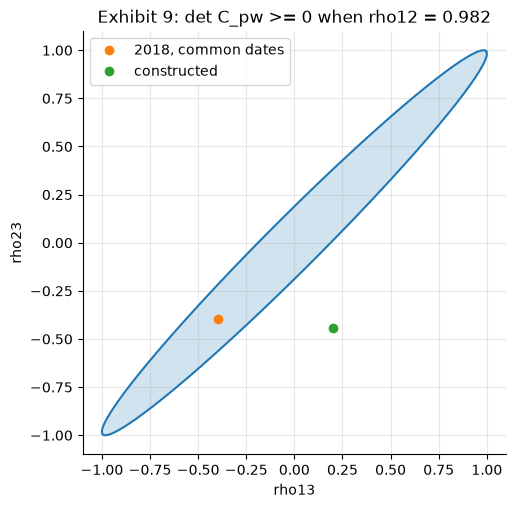

In [17]:
# Example 9 (constructed): pair correlations by calendar year, each pair on its common dates
pairs = [("0050", "00631L"), ("0050", "00679B"), ("00631L", "00679B")]
tab = {}
for a_, b_ in pairs:
    ds_ = sorted(set(etf[a_]) & set(etf[b_]))
    for y in range(2017, 2027):
        dd = [d for d in ds_ if d.startswith(str(y))]
        tab[(a_, b_, y)] = (np.corrcoef([etf[a_][d] for d in dd], [etf[b_][d] for d in dd])[0, 1], len(dd))
print(pl.DataFrame([{"pair": f"{a_}/{b_}", **{str(y): round(tab[(a_, b_, y)][0], 3) for y in range(2017, 2027)}} for a_, b_ in pairs]))
r12, r13, r23 = (round(tab[(*pairs[0], 2018)][0], 3), round(tab[(*pairs[1], 2023)][0], 3), round(tab[(*pairs[2], 2019)][0], 3))
print("chosen:", r12, r13, r23, "with T_ij", tab[(*pairs[0], 2018)][1], tab[(*pairs[1], 2023)][1], tab[(*pairs[2], 2019)][1])
Cn = np.array([[1, r12, r13], [r12, 1, r23], [r13, r23, 1]])     # C_pw: no single sample has this matrix
detC = 1 + 2 * r12 * r13 * r23 - r12**2 - r13**2 - r23**2
print(f"det C_pw = {detC:.6f}; x = (-1, 1, 1): x'C_pw x = {np.array([-1, 1, 1]) @ Cn @ np.array([-1, 1, 1]):.2f}")
adjC = detC * np.linalg.inv(Cn)                                   # the adjugate, from C_pw adj(C_pw) = det(C_pw) I
for j in range(3):
    xj = adjC[:, j]
    print(f"witness j = {j + 1}: adj(C_pw)_jj = {adjC[j, j]:.6f}, x'C_pw x = {xj @ Cn @ xj:.4f}"
          f" = det C_pw * adj(C_pw)_jj = {detC * adjC[j, j]:.4f}")
fails = sum(1 for y1, y2, y3 in permutations(range(2017, 2027), 3)
            if 1 + 2 * tab[(*pairs[0], y1)][0] * tab[(*pairs[1], y2)][0] * tab[(*pairs[2], y3)][0]
            - tab[(*pairs[0], y1)][0] ** 2 - tab[(*pairs[1], y2)][0] ** 2 - tab[(*pairs[2], y3)][0] ** 2 < 0)
print(f"assignments of three different years that fail: {fails} of 720")
d18 = [d for d in sorted(set(etf["0050"]) & set(etf["00631L"]) & set(etf["00679B"])) if d.startswith("2018")]
C18 = np.corrcoef(np.array([[etf[e][d] for e in ETFS] for d in d18]).T)
print(f"2018, {len(d18)} common dates:", C18[0, 1].round(3), C18[0, 2].round(3), C18[1, 2].round(3),
      f"det of the rounded matrix {np.linalg.det(C18.round(3)):.4f}")

t = np.linspace(0, 2 * np.pi, 400)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
u1 = np.array([1, 1]) / math.sqrt(2); u2 = np.array([1, -1]) / math.sqrt(2)
ell = np.outer(np.cos(t) * math.sqrt(1 + r12), u1) + np.outer(np.sin(t) * math.sqrt(1 - r12), u2)
ax.fill(ell[:, 0], ell[:, 1], alpha=0.2); ax.plot(ell[:, 0], ell[:, 1])
ax.plot([C18[0, 2]], [C18[1, 2]], "o", label="2018, common dates"); ax.plot([r13], [r23], "o", label="constructed")
ax.set_aspect("equal"); ax.set_xlabel("rho13"); ax.set_ylabel("rho23"); ax.legend()
ax.set_title("Exhibit 9: det C_pw >= 0 when rho12 = 0.982"); plt.show()

## Part 7 — Matrix calculus (Example 10, Exhibit 10)

By (10.8) the gradient of $\mathbf w^{\top}M\mathbf w$ is $(M+M^{\top})\mathbf w$; for the annualized variance it is $2A\hat\Sigma\mathbf w$. Central differences confirm it, and (10.9) prices a switch exactly. The sample volatility of the switch is what the switch would have done in 2008–2026, not a forecast.

In [18]:
var_a = lambda v: A * v @ S @ v
grad = 2 * A * S @ w
num = np.array([(var_a(w + 1e-6 * e) - var_a(w - 1e-6 * e)) / 2e-6 for e in np.eye(28)])
print("finite differences agree with 2A S w to 1e-8:", np.abs(num - grad).max() < 1e-8)
iG, iC = U28.index("GlassCeramic"), U28.index("CommunicationsInternet")
print(f"gradient: GlassCeramic {grad[iG]:.6f} (largest: {U28[int(np.argmax(grad))]}), "
      f"CommunicationsInternet {grad[iC]:.6f} (smallest: {U28[int(np.argmin(grad))]})")
Dl = np.zeros(28); Dl[iC], Dl[iG] = 1 / 28, -1 / 28
lin, quad = Dl @ grad, A * Dl @ S @ Dl
print(f"Example 10: {var_a(w):.7f} {lin:+.7f} {quad:+.7f} = {var_a(w) + lin + quad:.7f}; direct {var_a(w + Dl):.7f}")
print(f"volatility {math.sqrt(var_a(w)):.2%} -> {math.sqrt(var_a(w + Dl)):.2%}; linear term alone {math.sqrt(var_a(w) + lin):.2%}")

# (10.10) numerically: a PSD matrix (A S) and the indefinite symmetric part of the cross-term example
for name, Mx in (("A S, U28", A * S), ("M_sym of the cross-term example", Msym)):
    rng_pts = [(np.eye(len(Mx))[0], np.eye(len(Mx))[1], 0.5), (np.ones(len(Mx)) / len(Mx), np.eye(len(Mx))[-1], 0.3)]
    for xa, ya, om in rng_pts:                      # om is the mixing weight omega of (10.10)
        h = lambda v: v @ Mx @ v
        lhs = h(om * xa + (1 - om) * ya); rhs = om * h(xa) + (1 - om) * h(ya)
        print(f"{name}: h(mix) = {lhs:.6f}, chord = {rhs:.6f}, "
              f"identity holds to 1e-12: {abs(lhs - rhs + om * (1 - om) * h(xa - ya)) < 1e-12}")

finite differences agree with 2A S w to 1e-8: True
gradient: GlassCeramic 0.072303 (largest: GlassCeramic), CommunicationsInternet 0.027641 (smallest: CommunicationsInternet)
Example 10: 0.0248034 -0.0015951 +0.0001364 = 0.0233447; direct 0.0233447
volatility 15.75% -> 15.28%; linear term alone 15.23%
A S, U28: h(mix) = 0.039240, chord = 0.052786, identity holds to 1e-12: True
A S, U28: h(mix) = 0.026787, chord = 0.031268, identity holds to 1e-12: True
M_sym of the cross-term example: h(mix) = 1.500000, chord = 1.000000, identity holds to 1e-12: True
M_sym of the cross-term example: h(mix) = 1.255000, chord = 1.150000, identity holds to 1e-12: True


f = [0.6281 0.    ]: volatility 15.00%; gradient 2Mf = [0.0716 0.0204]; perpendicular to the curve: True
f = [0.     0.8908]: volatility 15.00%; gradient 2Mf = [0.0289 0.0505]; perpendicular to the curve: True
f = [0.437 0.437]: volatility 15.00%; gradient 2Mf = [0.064 0.039]; perpendicular to the curve: True


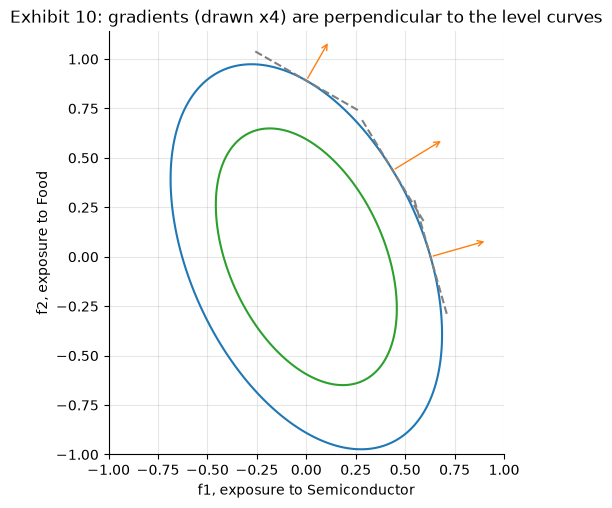

In [19]:
# Exhibit 10: level curves of the annualized variance of the exposures f to Semiconductor and Food, the rest
# of the book in cash (so f need not sum to 1), with the gradient 2Mf
Mg = AS3[np.ix_([0, 2], [0, 2])] / 1e4                  # that block of the printed A Sigma_3, in decimal units
gf = np.linspace(-1.0, 1.0, 401)
f1g, f2g = np.meshgrid(gf, gf)
var2 = Mg[0, 0] * f1g**2 + 2 * Mg[0, 1] * f1g * f2g + Mg[1, 1] * f2g**2
pts = [np.array([0.15 / math.sqrt(Mg[0, 0]), 0.0]), np.array([0.0, 0.15 / math.sqrt(Mg[1, 1])]),
       np.ones(2) * 0.15 / math.sqrt(np.ones(2) @ Mg @ np.ones(2))]
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.contour(f1g, f2g, var2, levels=[0.10**2, 0.15**2], colors=["tab:green", "tab:blue"])
for p in pts:
    gp = 2 * Mg @ p
    tan = np.array([-gp[1], gp[0]]) / np.linalg.norm(gp)       # direction along the level curve
    ax.annotate("", xy=p + 4 * gp, xytext=p, arrowprops=dict(arrowstyle="->", color="tab:orange"))
    ax.plot(*np.column_stack([p - 0.3 * tan, p + 0.3 * tan]), ls="--", color="grey")
    print(f"f = {p.round(4)}: volatility {math.sqrt(p @ Mg @ p):.2%}; gradient 2Mf = {gp.round(4)}; "
          f"perpendicular to the curve: {abs(tan @ gp) < 1e-15}")
ax.set_aspect("equal"); ax.set_xlabel("f1, exposure to Semiconductor"); ax.set_ylabel("f2, exposure to Food")
ax.set_title("Exhibit 10: gradients (drawn x4) are perpendicular to the level curves"); plt.show()

## Part 8 — Practice problems 4, 5, 6, 9 and 11

In [20]:
# Problem 4: rebuild A Sigma_3 from the printed C_3 and volatilities, then the mix (0.2, 0.3, 0.5)
vp = np.array([23.88, 19.07, 16.84])
R4 = np.outer(vp, vp) * C3p
print("rebuilt (%^2):\n", R4.round(2))
w4_ = np.array([0.2, 0.3, 0.5])
print(f"variance {w4_ @ R4 @ w4_:.2f}, volatility {math.sqrt(w4_ @ R4 @ w4_):.2f}%")

# Problem 5: (10.6) for S5
S5m = cov0(X[:, i5])
vb5, cb5 = np.mean(np.diag(S5m)), S5m[~np.eye(5, dtype=bool)].mean()
sp5 = vb5 / 5 + 0.8 * cb5
print(f"Problem 5: vbar {vb5:.4e}, cbar {cb5:.4e}; variance {sp5:.4e}, annual {A * sp5:.6f}, "
      f"volatility {math.sqrt(A * sp5):.2%}, limit {math.sqrt(A * cb5):.2%}")

# Problem 6: pivots of the printed A Sigma_3 by elimination without row exchanges
Kb = AS3[1:, 1:] - np.outer(AS3[1:, 0], AS3[0, 1:]) / AS3[0, 0]    # the block left after step 1
print("Problem 6: block after step 1\n", Kb.round(4))
print("pivots", pivots(AS3).round(2), "| all positive (PD):", bool(pivots(AS3).min() > 0))

rebuilt (%^2):
 [[570.25 261.85 162.06]
 [261.85 363.66 191.4 ]
 [162.06 191.4  283.59]]
variance 247.69, volatility 15.74%
Problem 5: vbar 2.0740e-04, cbar 9.0696e-05; variance 1.1404e-04, annual 0.027994, volatility 16.73%, limit 14.92%
Problem 6: block after step 1
 [[243.5299 116.8602]
 [116.8602 237.3775]]
pivots [570.34 243.53 181.3 ] | all positive (PD): True


In [21]:
# Problem 9: five points from Semiconductor to Food, with the printed A Sigma_3 in decimal units
Md = AS3 / 1e4
w9, d9 = np.array([0.5, 0.3, 0.2]), np.array([-0.05, 0.0, 0.05])
g9 = 2 * Md @ w9
print("gradient", g9.round(5), f"; linear {d9 @ g9:.6f}; quadratic {d9 @ Md @ d9:.6f}")
print(f"variance {w9 @ Md @ w9:.6f} -> {(w9 + d9) @ Md @ (w9 + d9):.6f}; "
      f"volatility {math.sqrt(w9 @ Md @ w9):.2%} -> {math.sqrt((w9 + d9) @ Md @ (w9 + d9)):.2%}")

# Problem 11: S5 three ways, (10.4), and the divisor
X5 = X[:, i5]; Xc5 = X5 - X5.mean(axis=0)
Sa, Sb, So = Xc5.T @ Xc5 / T, np.cov(X5, rowvar=False, ddof=0), sum(np.outer(r, r) for r in Xc5) / T
w5 = np.full(5, 0.2)
print("three ways agree within 1e-15:", max(np.abs(Sa - Sb).max(), np.abs(Sa - So).max()) < 1e-15,
      "| np.var(X @ w) = w @ S @ w within 1e-15:", abs(np.var(X5 @ w5) - w5 @ Sa @ w5) < 1e-15)
v0, v1 = math.sqrt(A * np.var(X5 @ w5)), math.sqrt(A * np.var(X5 @ w5, ddof=1))
print(f"volatility {v0:.4%} with divisor T, {v1:.4%} with ddof=1 (ratio {v1 / v0:.6f})")

gradient [0.07923 0.05566 0.03905] ; linear -0.002009; quadratic 0.000132
variance 0.032063 -> 0.030186; volatility 17.91% -> 17.37%
three ways agree within 1e-15: True | np.var(X @ w) = w @ S @ w within 1e-15: True
volatility 16.7313% with divisor T, 16.7332% with ddof=1 (ratio 1.000114)


### Extension: how much does diversification remove, year by year? (a stability check)

For each calendar year from 2009 to 2025, and 2026 to 8 October, compute the volatility of the equal-weight U28 book divided by the mean of the 28 sector volatilities, both from that year's returns. A ratio of 1 would mean no diversification; (10.6) says the ratio falls as the average covariance falls against the average variance. Plot the ratio by year and find the years with the lowest and the highest ratio. Two cautions: this compares years side by side, so it is a stability check, not an out-of-sample test; and the ratio is driven by how strongly the sectors move together, which LM11 measures with principal components. Draw no conclusion about future years.

In [22]:
# starter
yrs = np.array([int(d[:4]) for d in dates])
rows = []
for y in range(2009, 2027):
    m = yrs == y
    Sy = cov0(X[m])
    rows.append({"year": y, "returns": int(m.sum()), "ratio": math.sqrt(w @ Sy @ w) / np.sqrt(np.diag(Sy)).mean()})
ext = pl.DataFrame(rows)
print(ext.sort("ratio").head(1), ext.sort("ratio").tail(1))
# your plot and comments here

shape: (1, 3)
┌──────┬─────────┬──────────┐
│ year ┆ returns ┆ ratio    │
│ ---  ┆ ---     ┆ ---      │
│ i64  ┆ i64     ┆ f64      │
╞══════╪═════════╪══════════╡
│ 2017 ┆ 246     ┆ 0.563407 │
└──────┴─────────┴──────────┘ shape: (1, 3)
┌──────┬─────────┬──────────┐
│ year ┆ returns ┆ ratio    │
│ ---  ┆ ---     ┆ ---      │
│ i64  ┆ i64     ┆ f64      │
╞══════╪═════════╪══════════╡
│ 2020 ┆ 245     ┆ 0.808989 │
└──────┴─────────┴──────────┘
